Week 08: Boosting models

### What is a boosting model?
#### Boosting: Trains different homogenous models sequentially, aiming to correct errors in the previous model. ex XGBoost, AdaBoost, GBM 

### Goal: Use AdaBoost, Gradient Boost, and XGBoost to solve the regression problem `Sale Price` on the **Ames, Iowa housing data**


In [32]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.model_selection import train_test_split,  GridSearchCV, RepeatedStratifiedKFold
from sklearn.feature_selection import SelectKBest, VarianceThreshold
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

from sklearn.neighbors import  KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error as mse
from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestRegressor, BaggingRegressor, AdaBoostRegressor, GradientBoostingRegressor, StackingRegressor

from xgboost import XGBRegressor

In [33]:
ames = pd.read_csv('../data/ames.csv')
ames.head()


,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,Utilities,Lot_Config,Land_Slope,Neighborhood,Condition_1,Condition_2,Bldg_Type,House_Style,Overall_Qual,Overall_Cond,Year_Built,Year_Remod_Add,Roof_Style,Roof_Matl,Exterior_1st,Exterior_2nd,Mas_Vnr_Type,Mas_Vnr_Area,Exter_Qual,Exter_Cond,Foundation,Bsmt_Qual,Bsmt_Cond,Bsmt_Exposure,BsmtFin_Type_1,BsmtFin_SF_1,BsmtFin_Type_2,BsmtFin_SF_2,Bsmt_Unf_SF,Total_Bsmt_SF,Heating,Heating_QC,Central_Air,Electrical,First_Flr_SF,Second_Flr_SF,Low_Qual_Fin_SF,Gr_Liv_Area,Bsmt_Full_Bath,Bsmt_Half_Bath,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,Kitchen_Qual,TotRms_AbvGrd,Functional,Fireplaces,Fireplace_Qu,Garage_Type,Garage_Finish,Garage_Cars,Garage_Area,Garage_Qual,Garage_Cond,Paved_Drive,Wood_Deck_SF,Open_Porch_SF,Enclosed_Porch,Three_season_porch,Screen_Porch,Pool_Area,Pool_QC,Fence,Misc_Feature,Misc_Val,Mo_Sold,Year_Sold,Sale_Type,Sale_Condition,Sale_Price,Longitude,Latitude
0,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,141,31770,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,Gtl,North_Ames,Norm,Norm,OneFam,One_Story,Above_Average,Average,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112,Typical,Typical,CBlock,Typical,Good,Gd,BLQ,2,Unf,0,441,1080,GasA,Fair,Y,SBrkr,1656,0,0,1656,1,0,1,0,3,1,Typical,7,Typ,2,Good,Attchd,Fin,2,528,Typical,Typical,Partial_Pavement,210,62,0,0,0,0,No_Pool,No_Fence,NaN,0,5,2010,WD,Normal,215000,-93.619754,42.054035
1,One_Story_1946_and_Newer_All_Styles,Residential_High_Density,80,11622,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,Gtl,North_Ames,Feedr,Norm,OneFam,One_Story,Average,Above_Average,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0,Typical,Typical,CBlock,Typical,Typical,No,Rec,6,LwQ,144,270,882,GasA,Typical,Y,SBrkr,896,0,0,896,0,0,1,0,2,1,Typical,5,Typ,0,No_Fireplace,Attchd,Unf,1,730,Typical,Typical,Paved,140,0,0,0,120,0,No_Pool,Minimum_Privacy,NaN,0,6,2010,WD,Normal,105000,-93.619756,42.053014
2,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,81,14267,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,Gtl,North_Ames,Norm,Norm,OneFam,One_Story,Above_Average,Above_Average,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108,Typical,Typical,CBlock,Typical,Typical,No,ALQ,1,Unf,0,406,1329,GasA,Typical,Y,SBrkr,1329,0,0,1329,0,0,1,1,3,1,Good,6,Typ,0,No_Fireplace,Attchd,Unf,1,312,Typical,Typical,Paved,393,36,0,0,0,0,No_Pool,No_Fence,Gar2,12500,6,2010,WD,Normal,172000,-93.619387,42.052659
3,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,93,11160,Pave,No_Alley_Access,Regular,Lvl,AllPub,Corner,Gtl,North_Ames,Norm,Norm,OneFam,One_Story,Good,Average,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0,Good,Typical,CBlock,Typical,Typical,No,ALQ,1,Unf,0,1045,2110,GasA,Excellent,Y,SBrkr,2110,0,0,2110,1,0,2,1,3,1,Excellent,8,Typ,2,Typical,Attchd,Fin,2,522,Typical,Typical,Paved,0,0,0,0,0,0,No_Pool,No_Fence,NaN,0,4,2010,WD,Normal,244000,-93.617320,42.051245
4,Two_Story_1946_and_Newer,Residential_Low_Density,74,13830,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,OneFam,Two_Story,Average,Average,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0,Typical,Typical,PConc,Good,Typical,No,GLQ,3,Unf,0,137,928,GasA,Good,Y,SBrkr,928,701,0,1629,0,0,2,1,3,1,Typical,6,Typ,1,Typical,Attchd,Fin,2,482,Typical,Typical,Paved,212,34,0,0,0,0,No_Pool,Minimum_Privacy,NaN,0,3,2010,WD,Normal,189900,-93.638933,42.060899


In [34]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

print(ames.dtypes)

MS_SubClass            object
MS_Zoning              object
Lot_Frontage            int64
Lot_Area                int64
Street                 object
Alley                  object
Lot_Shape              object
Land_Contour           object
Utilities              object
Lot_Config             object
Land_Slope             object
Neighborhood           object
Condition_1            object
Condition_2            object
Bldg_Type              object
House_Style            object
Overall_Qual           object
Overall_Cond           object
Year_Built              int64
Year_Remod_Add          int64
Roof_Style             object
Roof_Matl              object
Exterior_1st           object
Exterior_2nd           object
Mas_Vnr_Type           object
Mas_Vnr_Area            int64
Exter_Qual             object
Exter_Cond             object
Foundation             object
Bsmt_Qual              object
Bsmt_Cond              object
Bsmt_Exposure          object
BsmtFin_Type_1         object
BsmtFin_SF

In [35]:
ames.shape

(2930, 81)

### Scatterplot of predictors against target

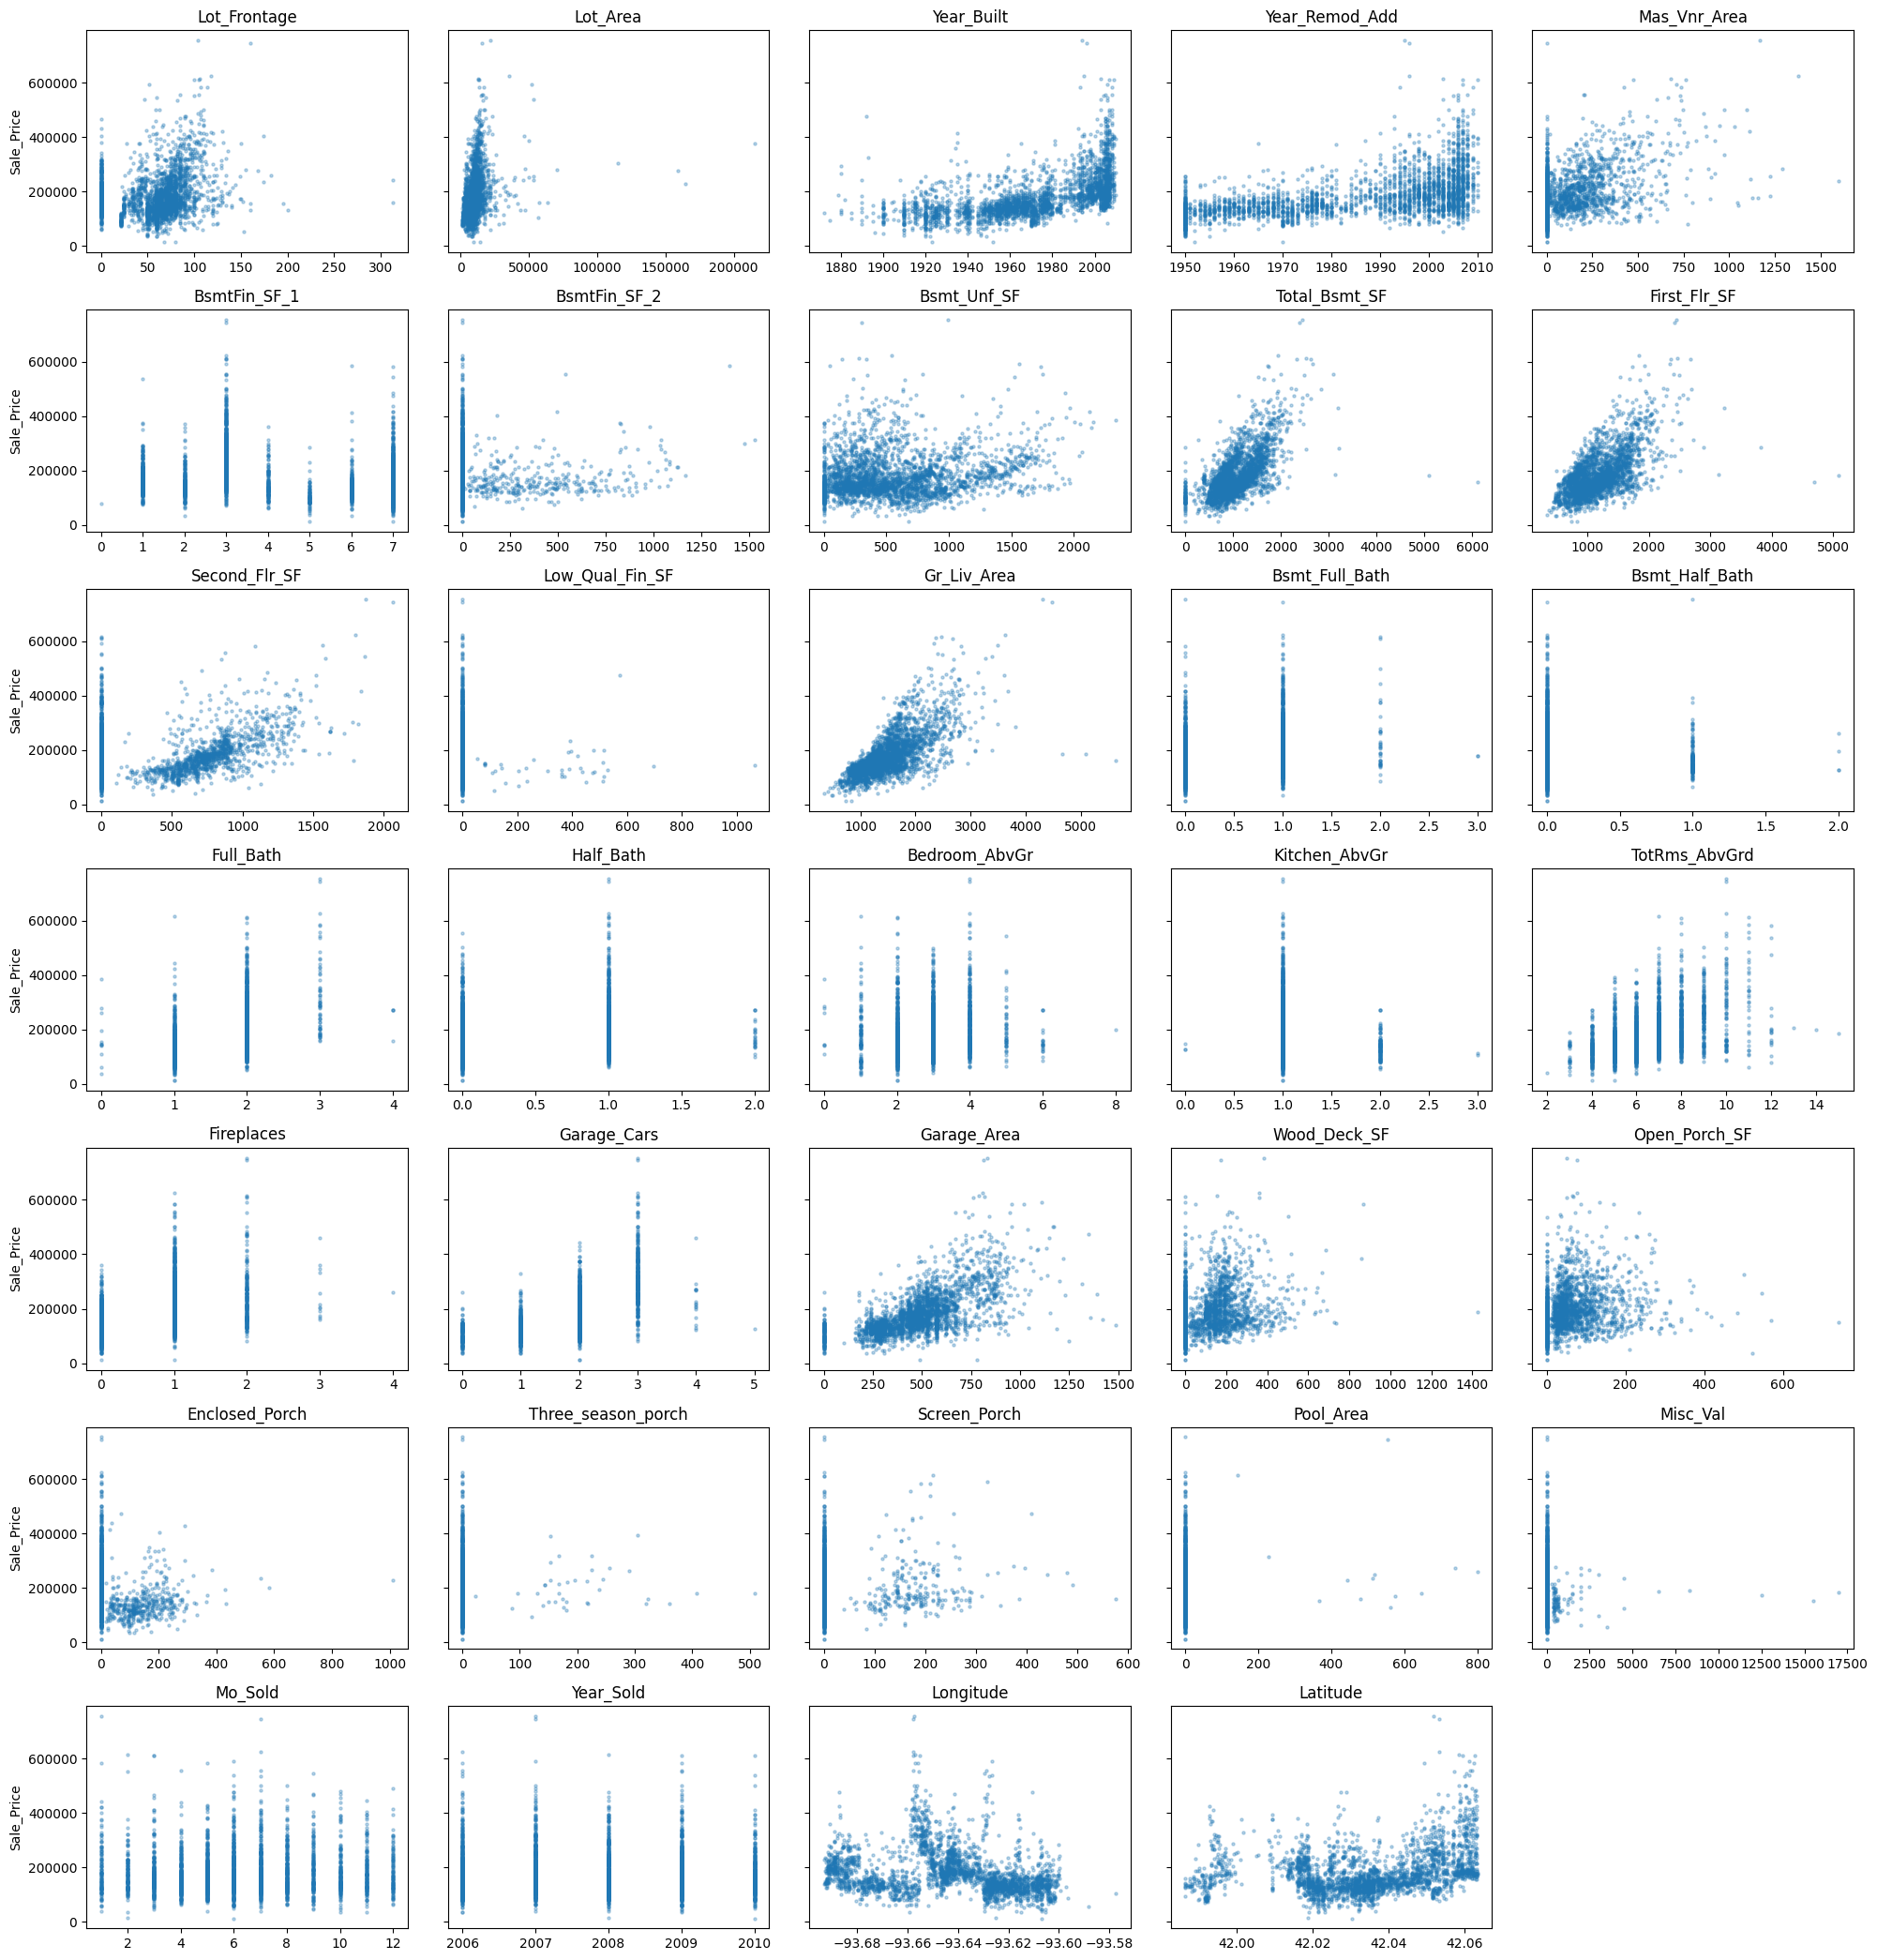

In [36]:
## Scatterplot of each numeric predictor against Sale_Price (categorical columns are left out)
num_predictors = ames.select_dtypes(include='number').columns.drop('Sale_Price')

n_cols = 5
n_rows = int(np.ceil(len(num_predictors) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows), sharey=True)

for ax, col in zip(axes.flat, num_predictors):
    ax.scatter(ames[col], ames['Sale_Price'], s=5, alpha=0.3)
    ax.set_title(col)

for ax in axes.flat[len(num_predictors):]:   ## hide unused panels
    ax.set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel('Sale_Price')

plt.tight_layout()
plt.show()

## Scatterplot of each categorical predictor against Sale_Price, with the category names on the x axis

### Also enlarged 




In [37]:
cat_predictors = ames.select_dtypes(include=['object', 'category']).columns

n_cols = 2
n_rows = int(np.ceil(len(cat_predictors) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 7 * n_rows), sharey=True)
rng = np.random.default_rng(42)

for ax, col in zip(axes.flat, cat_predictors):
    values = ames[col].astype(str)   ## missing values show up as 'nan'
    order = ames.groupby(values)['Sale_Price'].median().sort_values().index
    positions = values.map({cat: i for i, cat in enumerate(order)})
    jitter = rng.uniform(-0.2, 0.2, len(ames))
    ax.scatter(positions + jitter, ames['Sale_Price'], s=8, alpha=0.3)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=45, ha='right', fontsize=11)
    ax.tick_params(axis='y', labelsize=11)
    ax.set_title(col, fontsize=15)

for ax in axes.flat[len(cat_predictors):]:   ## hide unused panels
    ax.set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel('Sale_Price', fontsize=12)

plt.tight_layout()
plt.show()

## Pairwise Correlations
I use a heatmap, a list of strongest pairwise correlations, and `Variance Inflation Factor` (VIF).
# Variance Inflation Factor: 
A statistical metric that detects multicollinearity, and quantifies how much it affects a regression coefficient.

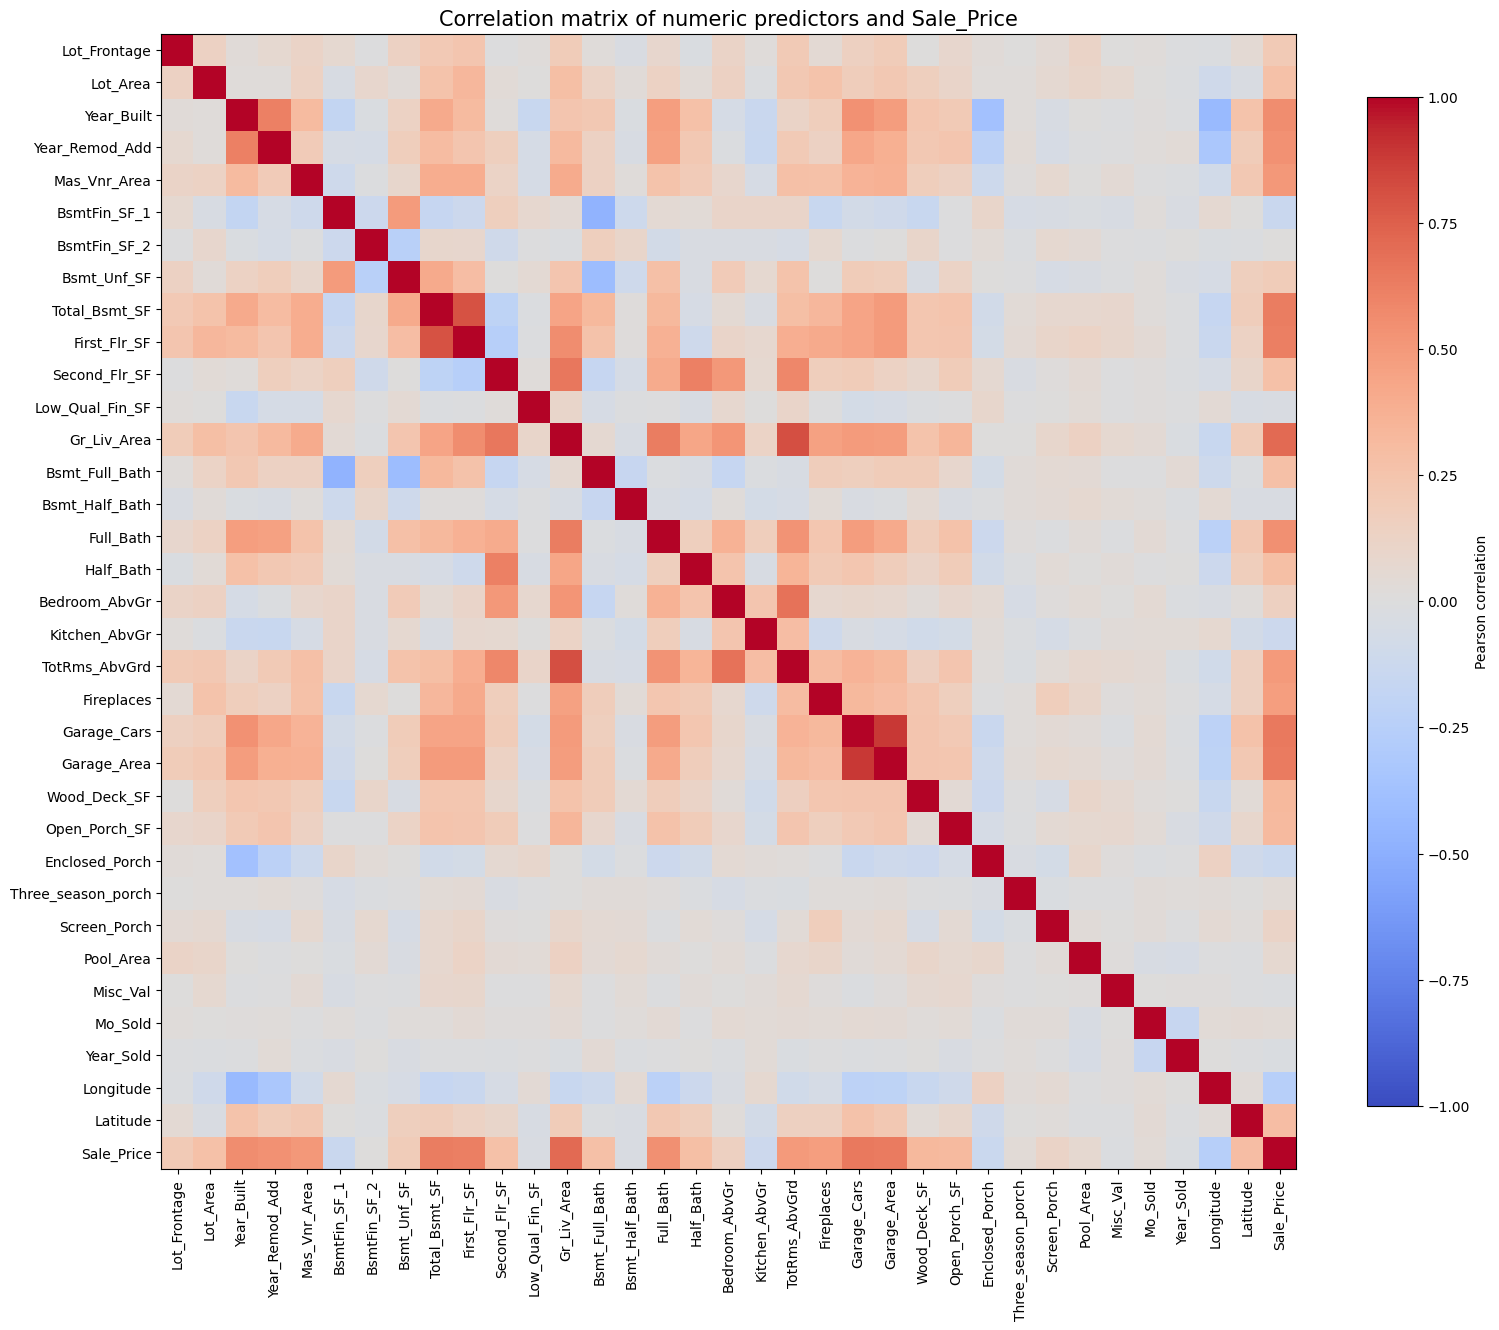

Predictor pairs with |r| > 0.6


,predictor_1,predictor_2,r
483,Garage_Cars,Garage_Area,0.890
336,Gr_Liv_Area,TotRms_AbvGrd,0.808
236,Total_Bsmt_SF,First_Flr_SF,0.800
426,Bedroom_AbvGr,TotRms_AbvGrd,0.673
286,Second_Flr_SF,Gr_Liv_Area,0.655
332,Gr_Liv_Area,Full_Bath,0.630
65,Year_Built,Year_Remod_Add,0.612
290,Second_Flr_SF,Half_Bath,0.612


Variance inflation factors


,VIF
Gr_Liv_Area,inf
First_Flr_SF,inf
Low_Qual_Fin_SF,inf
Second_Flr_SF,inf
Garage_Cars,5.8
Garage_Area,5.5
Total_Bsmt_SF,4.8
TotRms_AbvGrd,4.4
Year_Built,3.2
Bsmt_Unf_SF,3.1


In [38]:
## Pairwise correlations and collinearity among the numeric predictors
from sklearn.linear_model import LinearRegression

num_predictors = ames.select_dtypes(include='number').columns.drop('Sale_Price')
corr = ames[list(num_predictors) + ['Sale_Price']].corr()

## Heatmap of the correlation matrix (red = positive, blue = negative)
fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=10)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns, fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson correlation')
ax.set_title('Correlation matrix of numeric predictors and Sale_Price', fontsize=15)
plt.tight_layout()
plt.show()

## Strongly correlated predictor pairs (|r| > 0.6)
pred_corr = corr.loc[num_predictors, num_predictors]
upper = pred_corr.where(np.triu(np.ones(pred_corr.shape, dtype=bool), k=1))   ## each pair once, no diagonal
pairs = upper.stack().rename('r').reset_index()
pairs.columns = ['predictor_1', 'predictor_2', 'r']
pairs = pairs[pairs['r'].abs() > 0.6].sort_values('r', key=abs, ascending=False)
print('Predictor pairs with |r| > 0.6')
display(pairs.round(3))

## Collinearity: variance inflation factor, VIF = 1 / (1 - R^2), where R^2 comes from
## regressing each predictor on all the others. VIF above 10 is a common warning sign;
## inf means the predictor is an exact linear combination of others.
vif = {}
for col in num_predictors:
    others = ames[num_predictors.drop(col)]
    r2 = LinearRegression().fit(others, ames[col]).score(others, ames[col])
    vif[col] = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
vif = pd.Series(vif, name='VIF').sort_values(ascending=False)
print('Variance inflation factors')
display(vif.round(1).to_frame())

This dataset shows highly correlated variables, such as garage area and number of cars in garage (Garage_Cars).
Using previous observations I have this list of categories I am going to remove, trying to be judicious.

In [39]:
drop_cols = [
    ## redundant / collinear
    'First_Flr_SF', 'Second_Flr_SF', 'Low_Qual_Fin_SF', 'Garage_Cars', 'TotRms_AbvGrd',
    'Exterior_2nd', 'Garage_Cond', 'Bedroom_AbvGr',
    ## near-constant
    'Utilities', 'Street', 'Pool_QC', 'Pool_Area', 'Condition_2', 'Three_season_porch',
    'Roof_Matl', 'Heating', 'Misc_Feature', 'Misc_Val',
    ## no visible relationship with price
    'Mo_Sold', 'Year_Sold',
]

X_all = ames.drop(columns='Sale_Price')
text_cols = X_all.select_dtypes(include='object').columns
X_all[text_cols] = X_all[text_cols].astype('category')  
X_sub = X_all.drop(columns=drop_cols)
y_all = ames['Sale_Price']


for name, X_set in [('All predictors', X_all), ('Selected subset', X_sub)]:
    print('%-16s %2d predictors' % (name, X_set.shape[1]))

All predictors   80 predictors
Selected subset  60 predictors


"OneHotEncoder is the encoding strategy used when the downstream models are linear models while OrdinalEncoder is often a good strategy with tree-based models." - https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline.html

In [40]:
## List of the best (tuned) model from each section, to compare them all at the end.
## Each entry: {'name': ..., 'features': 'X_all' or 'X_sub', 'model': fitted pipeline}
## Run this once; running it again empties the list.
best_models = []

Use OrdinalEncoder for Sklearn Ensemble RandomForestClassifier, tune max_depth.
<br> I want to test every model on both x_all and x_sub to see how results are affected. Test time, accuracy, compare, all that.. <br>
Using randomforestclassifier, I must change the continuous results column to a categorical amount. 
I will label categories this way: < $5,000, < $25,000, etc depending on frequency.

In [41]:
## Random forest classifier on Sale_Price price categories, tuned on max_depth, for X_all and X_sub
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

## Copy of y with Sale_Price binned into price categories (left-closed: $100,000 falls in '<$150,000').
## A '<$25,000' class would hold only 2 houses, too few to train on, so it is part of '<$100,000'.
price_bins = [0, 100000, 150000, 200000, 300000, np.inf]
price_labels = ['<$100,000', '<$150,000', '<$200,000', '<$300,000', '$300,000+']
y_class = pd.cut(y_all, bins=price_bins, labels=price_labels, right=False)
print(y_class.value_counts(sort=False))

## Split once so X_all and X_sub are trained and tested on the same houses
X_all_train, X_all_test, y_class_train, y_class_test = train_test_split(
    X_all, y_class, stratify=y_class, random_state=42
)
X_sub_train = X_sub.loc[X_all_train.index]
X_sub_test = X_sub.loc[X_all_test.index]

params = {'randomforestclassifier__max_depth': [None, 5, 10, 15, 20, 30]}

rows = []
for name, X_tr_set, X_te_set in [('X_all', X_all_train, X_all_test), ('X_sub', X_sub_train, X_sub_test)]:
    cat_cols_set = X_tr_set.select_dtypes(include='category').columns
    ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1)
    rf_pipe = make_pipeline(
        make_column_transformer((ord_enc, cat_cols_set), remainder='passthrough'),
        RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    )

    grid_search = GridSearchCV(rf_pipe, param_grid=params, cv=5, scoring='accuracy')
    start = time.time()
    grid_search.fit(X_tr_set, y_class_train)
    stop = time.time()
    rf_best = grid_search.best_estimator_

    rows.append({
        'features': name,
        'predictors': X_tr_set.shape[1],
        'best max_depth': str(grid_search.best_params_['randomforestclassifier__max_depth']),
        'CV accuracy': grid_search.best_score_,
        'train accuracy': accuracy_score(y_class_train, rf_best.predict(X_tr_set)),
        'test accuracy': accuracy_score(y_class_test, rf_best.predict(X_te_set)),
        'fit time (s)': stop - start,
    })

    ## Save the tuned model to best_models (replace it if this cell is re-run)
    model_name = 'RandomForestClassifier (%s)' % name
    best_models = [m for m in best_models if m['name'] != model_name]
    best_models.append({'name': model_name, 'features': name, 'model': rf_best})

print('Saved models:', [m['name'] for m in best_models])
pd.DataFrame(rows).round(3)

Sale_Price
<$100,000     237
<$150,000    1016
<$200,000     801
<$300,000     638
$300,000+     238
Name: count, dtype: int64
Saved models: ['RandomForestClassifier (X_all)', 'RandomForestClassifier (X_sub)']


,features,predictors,best max_depth,CV accuracy,train accuracy,test accuracy,fit time (s)
0,X_all,80,20,0.778,1.0,0.778,12.829
1,X_sub,60,None,0.787,1.0,0.775,12.604


Using the smaller X where I removed categories worsened the test accuracy, as expected. It lowered the fit time by 0.2s and performed .09 score better than the full X during cross validation. 
<br>
Next we will do AdaBoost. <br>
Vary estimators, and learning rate<br>
Again, we compare with our smaller X and full X <br>

Max_depth= None

In [42]:
## AdaBoost regressor on Sale_Price (dollars), tuned on n_estimators and learning_rate, for X_all and X_sub.
## Base learner: decision tree with max_depth=None (fully grown).
## Uses the same train/test houses as the random forest cell above (run that cell first),
## but with the dollar price y_all instead of the price categories.
y_reg_train = y_all.loc[X_all_train.index]
y_reg_test = y_all.loc[X_all_test.index]

params = {
    'adaboostregressor__n_estimators': [50, 100, 200],
    'adaboostregressor__learning_rate': [0.01, 0.1, 1.0],
}

rows = []
for name, X_tr_set, X_te_set in [('X_all', X_all_train, X_all_test), ('X_sub', X_sub_train, X_sub_test)]:
    cat_cols_set = X_tr_set.select_dtypes(include='category').columns
    ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1)
    ada_pipe = make_pipeline(
        make_column_transformer((ord_enc, cat_cols_set), remainder='passthrough'),
        AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=None), random_state=42)
    )

    grid_search = GridSearchCV(ada_pipe, param_grid=params, cv=5, scoring='r2', n_jobs=-1)
    start = time.time()
    grid_search.fit(X_tr_set, y_reg_train)
    stop = time.time()
    ada_best = grid_search.best_estimator_

    rows.append({
        'features': name,
        'predictors': X_tr_set.shape[1],
        'best n_estimators': grid_search.best_params_['adaboostregressor__n_estimators'],
        'best learning_rate': grid_search.best_params_['adaboostregressor__learning_rate'],
        'CV R2': grid_search.best_score_,
        'train R2': ada_best.score(X_tr_set, y_reg_train),
        'test R2': ada_best.score(X_te_set, y_reg_test),
        'test RMSE ($)': np.sqrt(mse(y_reg_test, ada_best.predict(X_te_set))),
        'fit time (s)': stop - start,
    })

    ## Save the tuned model to best_models (replace it if this cell is re-run)
    model_name = 'AdaBoostRegressor (%s)' % name
    best_models = [m for m in best_models if m['name'] != model_name]
    best_models.append({'name': model_name, 'features': name, 'model': ada_best})

print('Saved models:', [m['name'] for m in best_models])
pd.DataFrame(rows).round(3)

Saved models: ['RandomForestClassifier (X_all)', 'RandomForestClassifier (X_sub)', 'AdaBoostRegressor (X_all)', 'AdaBoostRegressor (X_sub)']


,features,predictors,best n_estimators,best learning_rate,CV R2,train R2,test R2,test RMSE ($),fit time (s)
0,X_all,80,50,1.0,0.894,1.0,0.891,25231.940,21.415
1,X_sub,60,200,0.1,0.892,1.0,0.888,25555.584,13.948


Again, the full X tests better than the X with columns removed. 
### Should I switch up the removed columns?
Probably, Lets try just removing the categories with infinite VIF
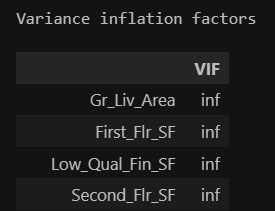

In [48]:
drop_cols1 = [

    'First_Flr_SF', 'Second_Flr_SF', 'Low_Qual_Fin_SF',
    'Gr_Liv_Area'
]
X_sub1 = X_all.drop(columns=drop_cols1)
X_sub1_train = X_sub1.loc[X_all_train.index]
X_sub1_test = X_sub1.loc[X_all_test.index]

I do not have a function so I will probably keep pasting similar chunks of code. 

In [49]:
params = {
    'adaboostregressor__n_estimators': [50, 100, 200],
    'adaboostregressor__learning_rate': [0.01, 0.1, 1.0],
}

rows = []
for name, X_tr_set, X_te_set in [('X_all', X_all_train, X_all_test), ('X_sub1', X_sub1_train, X_sub1_test)]:
    cat_cols_set = X_tr_set.select_dtypes(include='category').columns
    ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1)
    ada_pipe = make_pipeline(
        make_column_transformer((ord_enc, cat_cols_set), remainder='passthrough'),
        AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=None), random_state=42)
    )

    grid_search = GridSearchCV(ada_pipe, param_grid=params, cv=5, scoring='r2', n_jobs=-1)
    start = time.time()
    grid_search.fit(X_tr_set, y_reg_train)
    stop = time.time()
    ada_best = grid_search.best_estimator_

    rows.append({
        'features': name,
        'predictors': X_tr_set.shape[1],
        'best n_estimators': grid_search.best_params_['adaboostregressor__n_estimators'],
        'best learning_rate': grid_search.best_params_['adaboostregressor__learning_rate'],
        'CV R2': grid_search.best_score_,
        'train R2': ada_best.score(X_tr_set, y_reg_train),
        'test R2': ada_best.score(X_te_set, y_reg_test),
        'test RMSE ($)': np.sqrt(mse(y_reg_test, ada_best.predict(X_te_set))),
        'fit time (s)': stop - start,
    })

    ## Save the tuned model to best_models (replace it if this cell is re-run)
    model_name = 'AdaBoostRegressor (%s)' % name
    best_models = [m for m in best_models if m['name'] != model_name]
    best_models.append({'name': model_name, 'features': name, 'model': ada_best})

print('Saved models:', [m['name'] for m in best_models])
pd.DataFrame(rows).round(3)

Saved models: ['RandomForestClassifier (X_all)', 'RandomForestClassifier (X_sub)', 'AdaBoostRegressor (X_sub)', 'AdaBoostRegressor (X_all)', 'AdaBoostRegressor (X_sub1)']


,features,predictors,best n_estimators,best learning_rate,CV R2,train R2,test R2,test RMSE ($),fit time (s)
0,X_all,80,50,1.0,0.894,1.0,0.891,25231.940,17.348
1,X_sub1,76,200,0.1,0.864,1.0,0.879,26575.959,18.877


So X_all is probably the best option to run with, because it still performs the best. Unless I am messing something up. Maybe I will keep testing on X_all and X_sub (use X_sub1 for now) What columns did you remove and why?

In [52]:
## Gradient boosting regressor on the price categories ('<$100,000' ... '$300,000+'), tuned on loss and n_estimators, for X_all and X_sub1.
## A regressor needs numbers, so the categories are coded in price order: 0 = '<$100,000', 1 = '<$150,000', ... 4 = '$300,000+'.
## Predictions are rounded to the nearest category and scored by accuracy, same as the random forest classifier.
from sklearn.metrics import make_scorer

y_code_train = y_class_train.cat.codes
y_code_test = y_class_test.cat.codes

def rounded_accuracy(y_true, y_pred):
    y_pred = np.clip(np.round(y_pred), 0, len(price_labels) - 1)
    return accuracy_score(y_true, y_pred)

params = {
    'gradientboostingregressor__loss': ['squared_error', 'absolute_error', 'huber', 'quantile'],
    'gradientboostingregressor__n_estimators': [100, 200, 300],
    'gradientboostingregressor__learning_rate': [0.01, 0.1, 0.2,0.3,1]
}

rows = []
for name, X_tr_set, X_te_set in [('X_all', X_all_train, X_all_test), ('X_sub1', X_sub1_train, X_sub1_test)]:
    cat_cols_set = X_tr_set.select_dtypes(include='category').columns
    ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1)
    gbr_pipe = make_pipeline(
        make_column_transformer((ord_enc, cat_cols_set), remainder='passthrough'),
        GradientBoostingRegressor(random_state=42)
    )

    grid_search = GridSearchCV(gbr_pipe, param_grid=params, cv=5, scoring=make_scorer(rounded_accuracy), n_jobs=-1)
    start = time.time()
    grid_search.fit(X_tr_set, y_code_train)
    stop = time.time()
    gbr_best = grid_search.best_estimator_

    rows.append({
        'features': name,
        'predictors': X_tr_set.shape[1],
        'best loss': grid_search.best_params_['gradientboostingregressor__loss'],
        'best n_estimators': grid_search.best_params_['gradientboostingregressor__n_estimators'],
        'best learning_rate': grid_search.best_params_['gradientboostingregressor__learning_rate'],
        'CV accuracy': grid_search.best_score_,
        'train accuracy': rounded_accuracy(y_code_train, gbr_best.predict(X_tr_set)),
        'test accuracy': rounded_accuracy(y_code_test, gbr_best.predict(X_te_set)),
        'fit time (s)': stop - start,
    })

    ## Save the tuned model to best_models (replace it if this cell is re-run)
    model_name = 'GradientBoostingRegressor (%s)' % name
    best_models = [m for m in best_models if m['name'] != model_name]
    best_models.append({'name': model_name, 'features': name, 'model': gbr_best})

print('Saved models:', [m['name'] for m in best_models])
pd.DataFrame(rows).round(3)

Saved models: ['RandomForestClassifier (X_all)', 'RandomForestClassifier (X_sub)', 'AdaBoostRegressor (X_sub)', 'AdaBoostRegressor (X_all)', 'AdaBoostRegressor (X_sub1)', 'GradientBoostingRegressor (X_all)', 'GradientBoostingRegressor (X_sub1)']


,features,predictors,best loss,best n_estimators,best learning_rate,CV accuracy,train accuracy,test accuracy,fit time (s)
0,X_all,80,huber,200,0.1,0.786,0.926,0.783,48.824
1,X_sub1,76,squared_error,300,0.1,0.779,0.941,0.764,30.207


Training shows overfitting here. 

XGBoost is well-known for handling categorical data. I want to see how it will perform against the categorical target vs continuous target, where XGBoost will have to predict the price. We also do not need to use an encoder here. <br>
I really like this model, I saw someone on the internet disassemble a popular app store game which actually used xgboost to predict what will make you watch an ad.

In [ ]:
## XGBoost on the price categories (XGBClassifier) vs. the dollar price (XGBRegressor), for X_all, X_sub and X_sub1.
## No encoder: enable_categorical=True lets XGBoost split on the category columns directly.
## Tuned on booster, learning_rate and max_depth. 'gblinear' is not in the grid because it can't use categorical columns.
## Slow: about 12 minutes, mostly the 'dart' booster.
from xgboost import XGBClassifier

params = {
    'booster': ['gbtree', 'dart'],
    'learning_rate': [0.01, 0.1, 0.3],
    'max_depth': [3, 5, 7],
}

rows = []
for name, X_tr_set, X_te_set in [('X_all', X_all_train, X_all_test), ('X_sub', X_sub_train, X_sub_test),
                                 ('X_sub1', X_sub1_train, X_sub1_test)]:
    for target, xgb_model, y_tr, scoring in [
        ('categories', XGBClassifier(enable_categorical=True, random_state=42, n_jobs=1, verbosity=0), y_code_train, 'accuracy'),
        ('price ($)',  XGBRegressor(enable_categorical=True, random_state=42, n_jobs=1, verbosity=0), y_reg_train, 'r2'),
    ]:
        grid_search = GridSearchCV(xgb_model, param_grid=params, cv=5, scoring=scoring, n_jobs=-1)
        start = time.time()
        grid_search.fit(X_tr_set, y_tr)
        stop = time.time()
        xgb_best = grid_search.best_estimator_

        ## Score both on the price categories so they can be compared (predicted prices are binned the same way as y_class)
        pred = xgb_best.predict(X_te_set)
        if target == 'price ($)':
            pred = pd.cut(pred, bins=price_bins, labels=False, right=False)

        rows.append({
            'features': name,
            'target': target,
            'best booster': grid_search.best_params_['booster'],
            'best learning_rate': grid_search.best_params_['learning_rate'],
            'best max_depth': grid_search.best_params_['max_depth'],
            'CV score': grid_search.best_score_,
            'test accuracy (categories)': accuracy_score(y_code_test, pred),
            'fit time (s)': stop - start,
        })

        ## Save the tuned model to best_models (replace it if this cell is re-run)
        model_name = '%s (%s)' % (type(xgb_best).__name__, name)
        best_models = [m for m in best_models if m['name'] != model_name]
        best_models.append({'name': model_name, 'features': name, 'model': xgb_best})

print('Saved models:', [m['name'] for m in best_models])
print("CV score is accuracy for the categories target and R2 for the price target.")
pd.DataFrame(rows).round(3)